<a href="https://colab.research.google.com/github/saijeeitokar369/CPU_Scheduling_Simulator/blob/main/CPU_Scheduling_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CPU_Scheduling_Simulator**

### Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### Define Process Input

In [3]:

processes = [
    {"pid": "P1", "arrival": 0, "burst": 5, "priority": 2},
    {"pid": "P2", "arrival": 1, "burst": 3, "priority": 1},
    {"pid": "P3", "arrival": 2, "burst": 8, "priority": 4},
    {"pid": "P4", "arrival": 3, "burst": 6, "priority": 3}
]

print("Process Details")
print("-" * 50)

for p in processes:
    print(p)


Process Details
--------------------------------------------------
{'pid': 'P1', 'arrival': 0, 'burst': 5, 'priority': 2}
{'pid': 'P2', 'arrival': 1, 'burst': 3, 'priority': 1}
{'pid': 'P3', 'arrival': 2, 'burst': 8, 'priority': 4}
{'pid': 'P4', 'arrival': 3, 'burst': 6, 'priority': 3}


## **FCFS_Scheduling_Algorithm**

In [4]:

def fcfs_scheduling(processes):

    procs = sorted(processes, key=lambda x: x["arrival"])

    current_time = 0
    results = []
    gantt = []

    for p in procs:
        start_time = max(current_time, p["arrival"])
        completion_time = start_time + p["burst"]

        turnaround_time = completion_time - p["arrival"]
        waiting_time = turnaround_time - p["burst"]

        results.append({
            "PID": p["pid"],
            "Arrival Time": p["arrival"],
            "Burst Time": p["burst"],
            "Completion Time": completion_time,
            "Waiting Time": waiting_time,
            "Turnaround Time": turnaround_time
        })

        gantt.append((p["pid"], start_time, completion_time))
        current_time = completion_time

    return results, gantt


In [5]:

fcfs_results, fcfs_gantt = fcfs_scheduling(processes)

df_fcfs = pd.DataFrame(fcfs_results)

print("FCFS Scheduling Results")
display(df_fcfs)

print("Average Waiting Time:",
      df_fcfs["Waiting Time"].mean())

print("Average Turnaround Time:",
      df_fcfs["Turnaround Time"].mean())


FCFS Scheduling Results


,PID,Arrival Time,Burst Time,Completion Time,Waiting Time,Turnaround Time
0,P1,0,5,5,0,5
1,P2,1,3,8,4,7
2,P3,2,8,16,6,14
3,P4,3,6,22,13,19


Average Waiting Time: 5.75
Average Turnaround Time: 11.25


### Gantt Chart Visualization

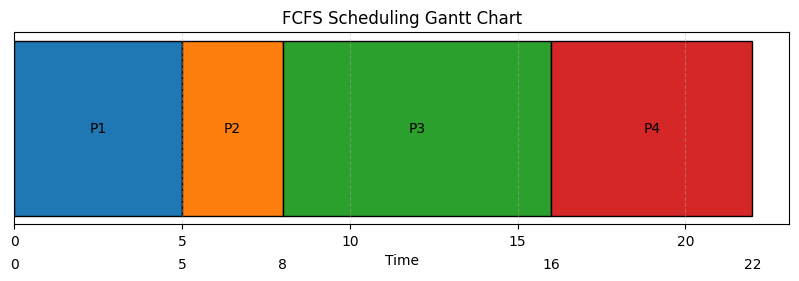

In [7]:

def draw_gantt_chart(gantt, title):

    fig, ax = plt.subplots(figsize=(10, 2.5))

    for pid, start, end in gantt:
        ax.barh(0, end - start, left=start,
                height=0.5, edgecolor="black")

        ax.text((start + end) / 2, 0, pid,
                ha="center", va="center")

        ax.text(start, -0.4, str(start),
                ha="center")

    ax.text(gantt[-1][2], -0.4,
            str(gantt[-1][2]), ha="center")

    ax.set_title(title)
    ax.set_yticks([])
    ax.set_xlabel("Time")
    ax.grid(axis="x", linestyle="--", alpha=0.4)

    plt.show()


draw_gantt_chart(fcfs_gantt, "FCFS Scheduling Gantt Chart")


## **SJF_Scheduling_Algorithm**

In [8]:

def sjf_scheduling(processes):

    remaining = processes.copy()
    current_time = 0
    results = []
    gantt = []

    while remaining:

        available = [
            p for p in remaining
            if p["arrival"] <= current_time
        ]

        if not available:
            current_time = min(p["arrival"] for p in remaining)
            continue

        p = min(available, key=lambda x: x["burst"])

        start_time = current_time
        completion_time = start_time + p["burst"]

        turnaround_time = completion_time - p["arrival"]
        waiting_time = turnaround_time - p["burst"]

        results.append({
            "PID": p["pid"],
            "Arrival Time": p["arrival"],
            "Burst Time": p["burst"],
            "Completion Time": completion_time,
            "Waiting Time": waiting_time,
            "Turnaround Time": turnaround_time
        })

        gantt.append((p["pid"], start_time, completion_time))

        current_time = completion_time
        remaining.remove(p)

    return results, gantt


In [9]:

sjf_results, sjf_gantt = sjf_scheduling(processes)

df_sjf = pd.DataFrame(sjf_results)

print("SJF Scheduling Results")
display(df_sjf)

print("Average Waiting Time:",
      df_sjf["Waiting Time"].mean())

print("Average Turnaround Time:",
      df_sjf["Turnaround Time"].mean())


SJF Scheduling Results


,PID,Arrival Time,Burst Time,Completion Time,Waiting Time,Turnaround Time
0,P1,0,5,5,0,5
1,P2,1,3,8,4,7
2,P4,3,6,14,5,11
3,P3,2,8,22,12,20


Average Waiting Time: 5.25
Average Turnaround Time: 10.75


### SJF Gantt Chart

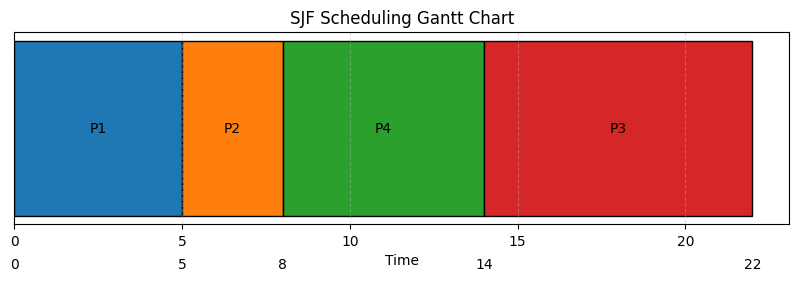

In [10]:

draw_gantt_chart(sjf_gantt, "SJF Scheduling Gantt Chart")


## **Round_Robin_Scheduling**

In [11]:

from collections import deque

def round_robin_scheduling(processes, quantum=2):

    remaining = {p["pid"]: p["burst"] for p in processes}
    arrival = {p["pid"]: p["arrival"] for p in processes}
    burst = {p["pid"]: p["burst"] for p in processes}

    queue = deque()
    current_time = 0
    completed = {}
    gantt = []

    procs = sorted(processes, key=lambda x: x["arrival"])
    i = 0

    while len(completed) < len(processes):

        while i < len(procs) and procs[i]["arrival"] <= current_time:
            queue.append(procs[i]["pid"])
            i += 1

        if not queue:
            current_time = procs[i]["arrival"]
            continue

        pid = queue.popleft()

        start = current_time
        execution = min(quantum, remaining[pid])

        current_time += execution
        remaining[pid] -= execution

        gantt.append((pid, start, current_time))

        while i < len(procs) and procs[i]["arrival"] <= current_time:
            queue.append(procs[i]["pid"])
            i += 1

        if remaining[pid] > 0:
            queue.append(pid)
        else:
            completed[pid] = current_time

    results = []

    for p in processes:
        ct = completed[p["pid"]]
        tat = ct - p["arrival"]
        wt = tat - p["burst"]

        results.append({
            "PID": p["pid"],
            "Arrival Time": p["arrival"],
            "Burst Time": p["burst"],
            "Completion Time": ct,
            "Waiting Time": wt,
            "Turnaround Time": tat
        })

    return results, gantt


In [12]:
# Time Quantum 2


rr_results, rr_gantt = round_robin_scheduling(
    processes, quantum=2
)

df_rr = pd.DataFrame(rr_results)

print("Round Robin Scheduling Results")
display(df_rr)

print("Average Waiting Time:",
      df_rr["Waiting Time"].mean())

print("Average Turnaround Time:",
      df_rr["Turnaround Time"].mean())


Round Robin Scheduling Results


,PID,Arrival Time,Burst Time,Completion Time,Waiting Time,Turnaround Time
0,P1,0,5,14,9,14
1,P2,1,3,11,7,10
2,P3,2,8,22,12,20
3,P4,3,6,20,11,17


Average Waiting Time: 9.75
Average Turnaround Time: 15.25


### Gantt Chart

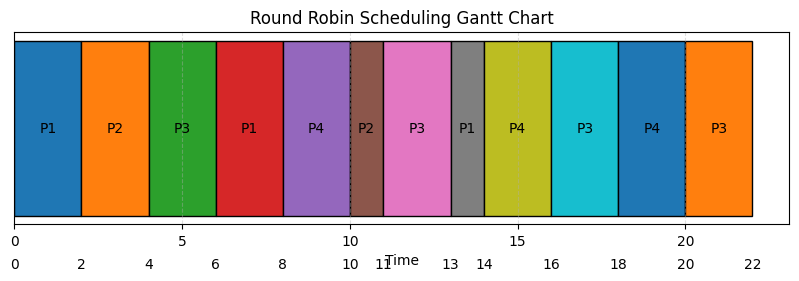

In [13]:

draw_gantt_chart(rr_gantt, "Round Robin Scheduling Gantt Chart")


## **Performance_Comparison**

In [17]:

comparison = pd.DataFrame({
    "Algorithm": ["FCFS", "SJF", "Round Robin"],

    "Average Waiting Time": [
        df_fcfs["Waiting Time"].mean(),
        df_sjf["Waiting Time"].mean(),
        df_rr["Waiting Time"].mean()
    ],

    "Average Turnaround Time": [
        df_fcfs["Turnaround Time"].mean(),
        df_sjf["Turnaround Time"].mean(),
        df_rr["Turnaround Time"].mean()
    ]
})

print("CPU Scheduling Performance Comparison")
display(comparison.round(2))


CPU Scheduling Performance Comparison


,Algorithm,Average Waiting Time,Average Turnaround Time
0,FCFS,5.75,11.25
1,SJF,5.25,10.75
2,Round Robin,9.75,15.25
